# Do device types fail by technology or by medical field?

**Question.** When medical device types are linked by how similar their adverse event reports read, do they group by medical field, by manufacturer, or by shared technology?

**Hypothesis (H).** Device types cluster by failure mechanism more than by FDA medical field: communities in the report-similarity network cut across medical fields, and this is not explained by manufacturers writing their reports the same way.

**Network.**
- **Nodes** are product codes, the FDA's kinds of device. Each report's own product code is used.
- **Text** is the `event_description` of each report, embedded with `all-MiniLM-L6-v2`.
- Each code is represented by the average of its report embeddings.
- **Edges:** every code is linked to its 5 most similar codes by cosine similarity.

**Decision rules, fixed before looking at results:**

| | rule |
|---|---|
| Field matters | field assortativity of the network is above every one of 1,000 label shuffles (p < 0.001) |
| Cross-field community | a community of 3 or more codes where no field holds 70% of codes **and** no manufacturer holds 70% of codes, so it is not one company's writing style |
| **H supported** | cross-field communities hold at least 25% of codes, the same holds with only between-manufacturer edges, and the problem-term network (the check) agrees with the text network |
| **H rejected** | cross-field communities hold under 10% of codes, so the network mostly mirrors medical fields |
| in between | partly supported |

**Check.** A second network is built from the FDA problem terms on the same reports (`product_problems` and `patient_problems`). It uses no embeddings. If both networks show the same structure, the result does not depend on the embedding model.

Run `data_import.ipynb` first. The sample and the embeddings are cached in `data/processed/`, so only the first run is slow (about 20 minutes on a laptop CPU).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import normalized_mutual_info_score

PROCESSED_DIR = Path("data/processed")
SAMPLE_PATH = PROCESSED_DIR / "embedding_sample.csv.gz"
EMBEDDINGS_PATH = PROCESSED_DIR / "embedding_sample_minilm.npy"

SEED = 42
MIN_REPORTS = 30       # a code needs this many usable descriptions to be a node
MAX_REPORTS = 300      # at most this many descriptions per code are embedded
MIN_CHARS, MAX_CHARS = 40, 5_000
K = 5                  # neighbours per code in the network
N_SHUFFLES = 1_000

COMMITTEES = {
    "AN": "Anesthesiology", "CH": "Clinical chemistry", "CV": "Cardiovascular", "DE": "Dental",
    "EN": "Ear, nose, throat", "GU": "Gastro and urology", "HE": "Hematology", "HO": "General hospital",
    "IM": "Immunology", "MG": "Medical genetics", "MI": "Microbiology", "NE": "Neurology",
    "OB": "Obstetrics and gynecology", "OP": "Ophthalmic", "OR": "Orthopedic", "PA": "Pathology",
    "PM": "Physical medicine", "RA": "Radiology", "SU": "General and plastic surgery", "TX": "Clinical toxicology",
}

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Sample the reports

A report is usable if its text is not a repeat of an earlier report for the same device (`is_repeat_text`), and its description has 40 to 5,000 characters. Shorter texts say little ("see narrative"), and longer ones are often registry extracts rather than one event.

Up to 300 usable reports are drawn at random per product code. More would mostly add insulin pumps and glucose monitors, without changing their average.

In [2]:
devices = pd.read_csv(PROCESSED_DIR / "pma_devices_2020_2025.csv", dtype=str)
reports = pd.read_csv(
    PROCESSED_DIR / "maude_reports.csv" if (PROCESSED_DIR / "maude_reports.csv").exists() else PROCESSED_DIR / "maude_reports.csv.gz",
    usecols=["mdr_report_key", "pma_number", "product_code", "event_type", "is_repeat_text", "text_chars",
             "product_problems", "patient_problems"],
    dtype=str,
)
reports["text_chars"] = reports["text_chars"].astype(int)

usable = reports[(reports["is_repeat_text"] == "False") & reports["text_chars"].between(MIN_CHARS, MAX_CHARS)]
per_code = usable["product_code"].value_counts()
kept_codes = per_code[per_code >= MIN_REPORTS].index

print(f"Usable reports: {len(usable):,} of {len(reports):,}")
print(f"Product codes: {per_code.size}, of which {kept_codes.size} have at least {MIN_REPORTS} usable reports")
print(f"Those codes cover {usable['product_code'].isin(kept_codes).mean():.1%} of usable reports")

Usable reports: 1,875,417 of 2,422,364
Product codes: 402, of which 201 have at least 30 usable reports
Those codes cover 99.9% of usable reports


In [3]:
if SAMPLE_PATH.exists():
    sample = pd.read_csv(SAMPLE_PATH, dtype=str)
else:
    sample = (
        usable[usable["product_code"].isin(kept_codes)]
        .sample(frac=1, random_state=SEED)
        .groupby("product_code").head(MAX_REPORTS)
        .drop(columns=["is_repeat_text"])
    )
    # The text file is 4 GB, so it is read in chunks and only sampled reports are kept.
    text_path = PROCESSED_DIR / "maude_text.csv"
    if not text_path.exists():
        text_path = PROCESSED_DIR / "maude_text.csv.gz"
    wanted = set(sample["mdr_report_key"])
    texts = []
    for chunk in pd.read_csv(text_path, usecols=["mdr_report_key", "event_description"], dtype=str, chunksize=200_000):
        texts.append(chunk[chunk["mdr_report_key"].isin(wanted)])
    texts = pd.concat(texts)
    sample = sample.merge(texts, on="mdr_report_key", how="inner").sort_values(["product_code", "mdr_report_key"])
    sample.to_csv(SAMPLE_PATH, index=False)

sample = sample.reset_index(drop=True)
assert sample["event_description"].notna().all()
assert sample["mdr_report_key"].is_unique
print(f"Sample: {len(sample):,} reports from {sample['product_code'].nunique()} product codes")
sample["product_code"].value_counts().describe().round(0).to_frame("reports per code")

Sample: 48,450 reports from 201 product codes


,reports per code
count,201.0
mean,241.0
std,94.0
min,30.0
25%,178.0
50%,300.0
75%,300.0
max,300.0


### Labels for each code

**Medical field.** The field FDA lists for the code in its approval records. If a code is missing there, the most common field of the devices it was reported under is used.

**Manufacturer.** The latest applicant name of the reported device, merged to the parent company. Names are reduced to their first word (so `Medtronic Minimed, Inc.` and `Medtronic Vascular` are both Medtronic), and a few old names are mapped to the company that bought them and now files the reports. A code's manufacturer is the one with most of its reports. This merge is rough and only meant to catch the big companies.

In [4]:
ALIASES = {
    "st": "abbott", "guidant": "boston", "micro": "medtronic", "covidien": "medtronic",
    "depuy": "johnson", "ethicon": "johnson", "mentor": "johnson", "biosense": "johnson",
    "physio-control": "stryker", "bard": "becton",
}


def company(name):
    first = re.sub(r"[^a-z\- ]", " ", str(name).lower()).split()[0]
    return ALIASES.get(first, first)


devices["company"] = devices["latest_applicant"].map(company)
sample["company"] = sample["pma_number"].map(devices.set_index("pma_number")["company"])

records = pd.read_csv(PROCESSED_DIR / "pma_records.csv", dtype=str, usecols=["product_code", "advisory_committee"]).dropna()
field_from_records = records.groupby("product_code")["advisory_committee"].agg(lambda s: s.mode()[0])
sample["device_field"] = sample["pma_number"].map(devices.set_index("pma_number")["advisory_committee"])
field_from_devices = sample.groupby("product_code")["device_field"].agg(lambda s: s.mode()[0])

codes = sample.groupby("product_code").agg(
    n_reports=("mdr_report_key", "size"),
    company=("company", lambda s: s.mode()[0]),
    company_share=("company", lambda s: s.value_counts(normalize=True).iloc[0]),
    harm_share=("event_type", lambda s: s.isin(["Death", "Injury"]).mean()),
)
codes["field_code"] = field_from_records.reindex(codes.index).fillna(field_from_devices)
codes["field"] = codes["field_code"].map(COMMITTEES)
codes["name"] = devices.drop_duplicates("product_code").set_index("product_code")["generic_name"].reindex(codes.index)

print(f"Field taken from approval records for {codes.index.isin(field_from_records.index).mean():.0%} of codes")
print(f"Codes whose reports all come from one company: {(codes['company_share'] == 1).mean():.0%}")
print(f"\nCodes per field:\n{codes['field'].value_counts().to_string()}")
print(f"\nCodes per company (top 10):\n{codes['company'].value_counts().head(10).to_string()}")

Field taken from approval records for 89% of codes
Codes whose reports all come from one company: 34%

Codes per field:
field
Cardiovascular                 78
Orthopedic                     24
Neurology                      20
Ophthalmic                     17
Clinical chemistry             16
Gastro and urology             10
General and plastic surgery     9
Immunology                      5
Ear, nose, throat               5
Microbiology                    4
Anesthesiology                  4
Obstetrics and gynecology       3
Pathology                       2
Radiology                       2
General hospital                1
Dental                          1

Codes per company (top 10):
company
medtronic    33
abbott       27
johnson      18
boston       13
alcon         7
roche         6
w             4
abiomed       3
edwards       3
allergan      3


### What the text looks like

Three random descriptions from each of the three largest companies. Repeated openings such as "It was reported that" are company style, which is why the manufacturer has to be controlled for.

In [5]:
pd.set_option("display.max_colwidth", 220)
top_companies = sample["company"].value_counts().index[:3]
(
    sample[sample["company"].isin(top_companies)]
    .groupby("company").sample(3, random_state=SEED)[["company", "product_code", "event_description"]]
    .assign(event_description=lambda df: df["event_description"].str[:220])
)

,company,product_code,event_description
385,abbott,DSQ,"IT WAS REPORTED THAT THE PATIENT DEVELOPED A LEFT EMPYEMA STATUS-POST VIDEO-ASSISTED THORACOSCOPIC SURGERY (VATS), 3 TIMES, AND TRACHEOSTOMY ON 2022. THE PATIENT HAD ACUTE KIDNEY INJURY (AKI), SEVERE DECONDITIONING, ..."
25368,abbott,NGV,"IT WAS REPORTED THAT ON 2023, A 22MM AMPLATZER AMULET LEFT ATRIAL APPENDAGE OCCLUDER WAS IMPLANTED WITH A 12F AMPLATZER TORQVUE 45X45 DELIVERY SHEATH. THERE WAS NO DIFFICULTY EXPERIENCED DURING THE PROCEDURE AND THE ..."
36128,abbott,OOI,THE CUSTOMER REPORTED A LEAK ON THE ALINITY M SYSTEM SN (SERIAL NUMBER) . THE CUSTOMER REPORTED A LEAK FROM THE SYSTEM SOLUTION DRAWER OF THE ALINITY M SYSTEM. THE CUSTOMER STATED THAT THE LIQUID LEAKED ONTO THE FLOO...
34,johnson,DRF,IT WAS REPORTED THAT A PATIENT UNDERWENT AN AVRT (ATRIOVENTRICULAR NODAL REENTRANT TACHYCARDIA) ABLATION PROCEDURE WITH A NAVISTAR' ELECTROPHYSIOLOGY CATHETER AND THE PATIENT SUFFERED A SOFT TISSUE INJURY REQUIRING S...
7971,johnson,LMG,IT WAS REPORTED THAT A PATIENT UNDERWENT A LAPAROSCOPIC RADICAL PROSTATECTOMY PROCEDURE ON 2021 AND ABSORBABLE HEMOSTAT WAS USED. THE ABSORBABLE HEMOSTAT WAS USED AROUND THE BLADDER AFTER TOTAL RESECTION. AFTER LEAVI...
10847,johnson,LPH,"IT WAS REPORTED THAT A SINGLE STAGE (DOUBLE SETUP) HIP REVISED DUE TO INFECTION. ALL PARTS WERE REMOVED AND A NEW TOTAL HIP CONSTRUCT WAS PUT IN ITS PLACE AFTER I&D AND REDRAPING. DOI : 2022, DOR: 2022, AFFECTED SIDE..."
24676,medtronic,NBW,THE CUSTOMER REPORTED THAT HER BLOOD GLUCOSE READINGS FROM 2020 TO 2020 WERE NOT BEING STORED IN THE MEMORY OF THE CONTOUR PLUS LINK 2.4 METER. THERE WAS NO ALLEGATION OF AN ADVERSE EVENT. THE CUSTOMER WAS ADVISED TO...
14444,medtronic,LZG,IT WAS REPORTED TO MEDTRONIC MINIMED THAT THE CUSTOMER EXPERIENCED KEYPAD ISSUE/BUTTON ERROR. THE CUSTOMER REPORTED NO ADVERSE EVENT. THE EVENT INVOLVED PRODUCT(S) MMT-712EWS. TROUBLESHOOTING WAS PERFORMED AND ALL BU...
24772,medtronic,NBW,THE CUSTOMER FROM SWEDEN REPORTED THAT SHE WAS OUT ON A WALK WITH HER FRIEND WHEN SHE EXPERIENCED A HYPOGLYCEMIC EVENT. THE CUSTOMER FELL DOWN AND BECAME UNRESPONSIVE. THE CUSTOMER'S FRIEND TESTED THE CUSTOMER'S BLOO...


## 2. Embed the descriptions

`all-MiniLM-L6-v2` is a small, widely used sentence model. Texts are cut at 128 tokens, which keeps the start of each description, where the event is usually stated. Embeddings are normalised, so a dot product is a cosine similarity.

In [6]:
if EMBEDDINGS_PATH.exists():
    embeddings = np.load(EMBEDDINGS_PATH)
else:
    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")
    model.max_seq_length = 128
    embeddings = model.encode(
        sample["event_description"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False
    ).astype(np.float32)
    np.save(EMBEDDINGS_PATH, embeddings)

assert len(embeddings) == len(sample), "embeddings do not match the sample; delete both cache files and rerun"
embeddings.shape

/Users/usuario/opt/anaconda3/envs/socialgraphs/lib/python3.11/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


(48450, 384)

## 3. Build the network

Each code's vector is the average of its report embeddings, normalised again. Each code is then linked to its 5 nearest codes. A link kept by both ends is still one edge, weighted by the cosine similarity.

In [7]:
def centroids(vectors, groups, order):
    frame = pd.DataFrame(vectors).groupby(groups.values).mean().loc[order]
    matrix = frame.to_numpy()
    return matrix / np.linalg.norm(matrix, axis=1, keepdims=True)


def knn_graph(similarity, labels, k):
    graph = nx.Graph()
    graph.add_nodes_from(labels)
    sim = similarity.copy()
    np.fill_diagonal(sim, -np.inf)
    for i, row in enumerate(sim):
        for j in np.argsort(row)[-k:]:
            graph.add_edge(labels[i], labels[j], weight=float(similarity[i, j]))
    return graph


order = codes.index.to_numpy()
text_vectors = centroids(embeddings, sample["product_code"], order)
text_sim = text_vectors @ text_vectors.T
G = knn_graph(text_sim, order, K)
for column in ["field", "company"]:
    nx.set_node_attributes(G, codes[column].to_dict(), column)

upper = text_sim[np.triu_indices(len(order), 1)]
print(f"Nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}, connected parts: {nx.number_connected_components(G)}")
print(f"Cosine similarity between code averages: median {np.median(upper):.2f}, range {upper.min():.2f}-{upper.max():.2f}")
print(f"Similarity of linked pairs: median {np.median([w for *_, w in G.edges(data='weight')]):.2f}")

Nodes: 201, edges: 749, connected parts: 1
Cosine similarity between code averages: median 0.45, range 0.07-1.00
Similarity of linked pairs: median 0.76


## 4. Do links follow medical field and manufacturer?

**Assortativity** measures whether links join codes with the same label: 0 means no more than chance, 1 means every link stays within a label. To judge whether a value is high, the labels are shuffled across codes 1,000 times, keeping the network fixed.

In [8]:
def label_test(graph, labels, n_shuffles=N_SHUFFLES):
    nodes = list(graph.nodes)
    values = labels.reindex(nodes).to_numpy()
    observed = nx.attribute_assortativity_coefficient(graph, labels.name)
    same = np.mean([values[nodes.index(u)] == values[nodes.index(v)] for u, v in graph.edges])
    null = []
    for _ in range(n_shuffles):
        nx.set_node_attributes(graph, dict(zip(nodes, rng.permutation(values))), "shuffled")
        null.append(nx.attribute_assortativity_coefficient(graph, "shuffled"))
    null = np.array(null)
    return {
        "assortativity": observed,
        "null mean": null.mean(),
        "null 99th percentile": np.quantile(null, 0.99),
        "p (one-sided)": (np.sum(null >= observed) + 1) / (n_shuffles + 1),
        "share of edges within label": same,
    }


tests = pd.DataFrame({label: label_test(G, codes[label]) for label in ["field", "company"]}).T
tests.round(3)

,assortativity,null mean,null 99th percentile,p (one-sided),share of edges within label
field,0.643,-0.006,0.025,0.001,0.714
company,0.174,-0.006,0.015,0.001,0.235


Field and company overlap: Medtronic, for example, makes most of the cardiovascular codes. To separate them, the next table looks at every pair of codes, not only linked ones, and splits the average similarity by whether the two share a field and whether they share a company.

In [9]:
i, j = np.triu_indices(len(order), 1)
pairs = pd.DataFrame({
    "similarity": text_sim[i, j],
    "same_field": codes["field"].to_numpy()[i] == codes["field"].to_numpy()[j],
    "same_company": codes["company"].to_numpy()[i] == codes["company"].to_numpy()[j],
})
pair_table = pairs.pivot_table(index="same_field", columns="same_company", values="similarity", aggfunc=["mean", "size"])
pair_table.round(3)

mean          size      
same_company  False  True   False True 
same_field                             
False         0.432  0.492  15620   637
True          0.557  0.629   3294   549

In [10]:
cross_company = nx.Graph([(u, v, d) for u, v, d in G.edges(data=True) if codes.at[u, "company"] != codes.at[v, "company"]])
nx.set_node_attributes(cross_company, codes["field"].to_dict(), "field")
cross_test = label_test(cross_company, codes["field"])
print(f"Edges between different companies: {cross_company.number_of_edges()} of {G.number_of_edges()}")
pd.Series(cross_test, name="field, between-company edges only").round(3).to_frame()

Edges between different companies: 573 of 749


,"field, between-company edges only"
assortativity,0.600
null mean,-0.007
null 99th percentile,0.030
p (one-sided),0.001
share of edges within label,0.681


## 5. Communities

Communities are found with the Louvain method. It is random, so it runs with 20 seeds and keeps the split with the highest modularity. The agreement between seeds (NMI, 1 = identical) shows how stable the split is.

NMI with field and with company says how much the communities match each label. It is compared with the same score after shuffling the labels.

In [11]:
def best_partition(graph, seeds=range(20)):
    runs = [nx.community.louvain_communities(graph, weight="weight", seed=s) for s in seeds]
    scores = [nx.community.modularity(graph, run, weight="weight") for run in runs]
    as_labels = [pd.Series({n: c for c, members in enumerate(run) for n in members}) for run in runs]
    best = int(np.argmax(scores))
    nodes = list(graph.nodes)
    stability = np.mean([normalized_mutual_info_score(as_labels[best][nodes], other[nodes]) for other in as_labels])
    return as_labels[best], scores[best], stability


def nmi_test(partition, labels, n_shuffles=N_SHUFFLES):
    observed = normalized_mutual_info_score(labels[order], partition[order])
    null = [normalized_mutual_info_score(rng.permutation(labels[order].to_numpy()), partition[order]) for _ in range(n_shuffles)]
    return observed, float(np.mean(null))


codes["community"], modularity, stability = best_partition(G)
print(f"{codes['community'].nunique()} communities, modularity {modularity:.2f}, agreement between seeds (NMI) {stability:.2f}")
for label in ["field", "company"]:
    observed, null = nmi_test(codes["community"], codes[label])
    print(f"NMI with {label}: {observed:.2f} (shuffled labels: {null:.2f})")

10 communities, modularity 0.76, agreement between seeds (NMI) 0.96


NMI with field: 0.66 (shuffled labels: 0.15)


NMI with company: 0.51 (shuffled labels: 0.36)


In [12]:
def describe_communities(codes):
    rows = []
    for c, group in codes.groupby("community"):
        rows.append({
            "community": c,
            "codes": len(group),
            "fields": group["field"].nunique(),
            "top_field": group["field"].value_counts().index[0],
            "top_field_share": group["field"].value_counts(normalize=True).iloc[0],
            "companies": group["company"].nunique(),
            "top_company": group["company"].value_counts().index[0],
            "top_company_share": group["company"].value_counts(normalize=True).iloc[0],
        })
    table = pd.DataFrame(rows).set_index("community")
    table["cross_field"] = (table["codes"] >= 3) & (table["top_field_share"] < 0.7) & (table["top_company_share"] < 0.7)
    return table.sort_values("codes", ascending=False)


communities = describe_communities(codes)
cross_share = communities.loc[communities["cross_field"], "codes"].sum() / len(codes)
print(f"Codes in cross-field communities: {cross_share:.0%}")
communities.round(2)

Codes in cross-field communities: 29%


,codes,fields,top_field,top_field_share,companies,top_company,top_company_share,cross_field
community,,,,,,,,
7,34,2,Cardiovascular,0.82,15,abbott,0.26,False
9,28,9,Neurology,0.46,18,medtronic,0.21,True
8,23,2,Cardiovascular,0.96,9,abbott,0.26,False
0,21,3,Clinical chemistry,0.76,6,medtronic,0.57,False
4,21,2,Cardiovascular,0.95,9,abbott,0.33,False
1,20,6,Gastro and urology,0.40,14,johnson,0.20,True
3,18,3,Orthopedic,0.83,12,johnson,0.33,False
5,17,1,Ophthalmic,1.00,9,alcon,0.41,False
6,11,3,Immunology,0.45,5,roche,0.55,True


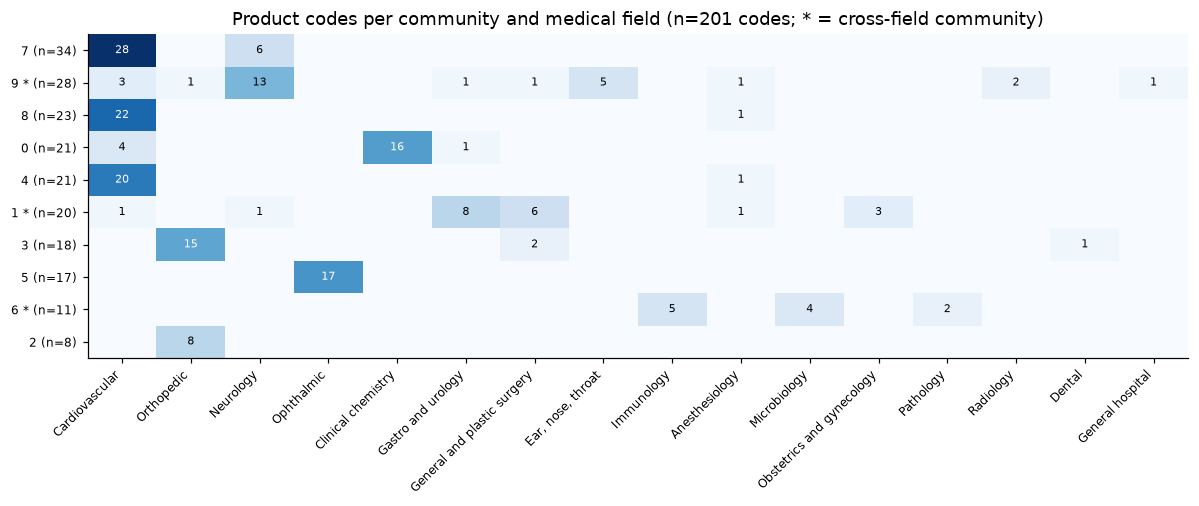

In [13]:
crosstab = pd.crosstab(codes["community"], codes["field"]).loc[communities.index]
crosstab = crosstab[crosstab.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 0.32 * len(crosstab) + 1.5))
image = ax.imshow(crosstab.to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(crosstab.shape[1]), crosstab.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(crosstab)), [
    f"{c}{' *' if communities.at[c, 'cross_field'] else ''} (n={communities.at[c, 'codes']})" for c in crosstab.index
], fontsize=8)
for (r, c), v in np.ndenumerate(crosstab.to_numpy()):
    if v:
        ax.text(c, r, v, ha="center", va="center", fontsize=7, color="white" if v > crosstab.to_numpy().max() / 2 else "black")
ax.set(title=f"Product codes per community and medical field (n={len(codes)} codes; * = cross-field community)")
plt.tight_layout()

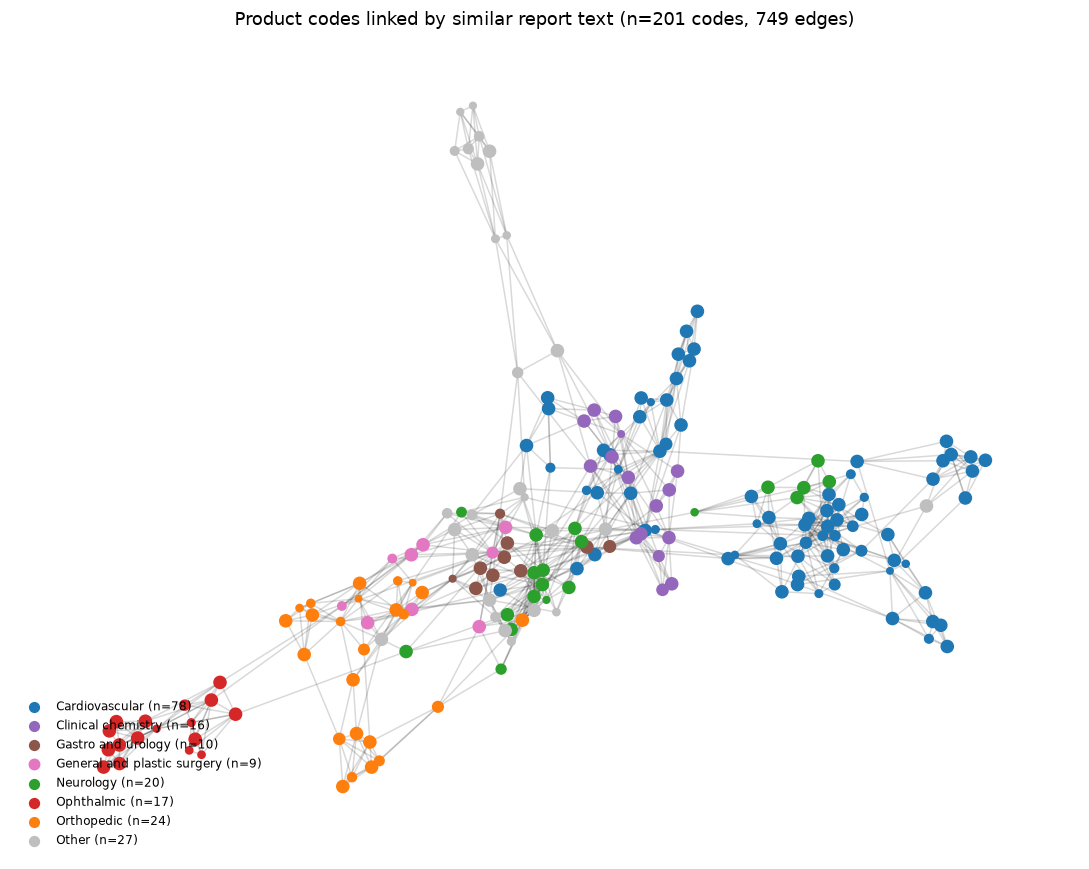

In [14]:
fields_shown = codes["field"].value_counts().index[:7]
palette = dict(zip(fields_shown, plt.cm.tab10.colors))
position = nx.spring_layout(G, weight="weight", seed=SEED)

fig, ax = plt.subplots(figsize=(10, 8))
nx.draw_networkx_edges(G, position, alpha=0.15, ax=ax)
for field, group in codes.groupby(codes["field"].where(codes["field"].isin(fields_shown), "Other")):
    nx.draw_networkx_nodes(
        G, position, nodelist=list(group.index), node_size=12 + group["n_reports"] / 6,
        node_color=[palette.get(field, (0.75, 0.75, 0.75))], label=f"{field} (n={len(group)})", ax=ax,
    )
ax.legend(fontsize=8, loc="lower left", frameon=False)
ax.set(title=f"Product codes linked by similar report text (n={G.number_of_nodes()} codes, {G.number_of_edges()} edges)")
ax.axis("off")
plt.tight_layout()

### What the cross-field communities share

For each cross-field community: its codes, the words that set its descriptions apart (TF-IDF over all communities), and the FDA problem terms most over-represented in it (lift = share in the community ÷ share overall, among terms in at least 5% of its reports).

In [15]:
sample["community"] = sample["product_code"].map(codes["community"])
community_text = sample.groupby("community")["event_description"].apply(" ".join)
tfidf = TfidfVectorizer(stop_words="english", min_df=2, max_df=0.5, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", sublinear_tf=True)
weights = tfidf.fit_transform(community_text)
vocabulary = np.array(tfidf.get_feature_names_out())


def problem_terms(frame):
    terms = (frame["product_problems"].fillna("") + "; " + frame["patient_problems"].fillna("")).str.split("; ")
    return terms.explode().str.strip().loc[lambda s: s != ""]


all_terms = problem_terms(sample).value_counts(normalize=True)

for c in communities.index[communities["cross_field"]]:
    members = codes[codes["community"] == c].sort_values("n_reports", ascending=False)
    in_community = sample[sample["community"] == c]
    counts = problem_terms(in_community).value_counts()
    share = counts / len(in_community)
    lift = (counts / counts.sum() / all_terms.reindex(counts.index)).where(share >= 0.05).dropna().nlargest(6)
    words = vocabulary[np.argsort(weights[community_text.index.get_loc(c)].toarray().ravel())[-10:][::-1]]

    print(f"=== Community {c}: {len(members)} codes, {members['field'].nunique()} fields, {members['company'].nunique()} companies")
    for code_, row in members.head(12).iterrows():
        print(f"   {code_}  {row['field']:<28} {row['company']:<12} {str(row['name'])[:60]}")
    print(f"   distinctive words: {', '.join(words)}")
    print(f"   over-represented problems: {'; '.join(f'{t} (x{v:.1f})' for t, v in lift.items())}\n")

=== Community 9: 28 codes, 9 fields, 18 companies
   QLK  Neurology                    mainstay     Stimulator, neuromuscular, lower back muscles, totally impla
   MNQ  Anesthesiology               inspire      Stimulator, hypoglossal nerve, implanted, apnea
   PJS  Neurology                    medtronic    nan
   NZK  Neurology                    novocure     Stimulator, low electric field, tumor treatment
   NHL  Neurology                    boston       Stimulator, electrical, implanted, for parkinsonian symptoms
   MVK  Cardiovascular               zoll         Wearable automated external defibrillator
   MUZ  Neurology                    livanova     nan
   EZW  Gastro and urology           medtronic    Stimulator, electrical, implantable, for incontinence
   MRM  Cardiovascular               biotronik    DEFIBRILLATOR, IMPLANTABLE, DUAL-CHAMBER
   MPV  Ear, nose, throat            med-el       Implant, hearing, active, middle ear, partially implanted
   MHY  Neurology            

## 6. Check: the problem-term network

The same network is built without embeddings. Each code becomes a TF-IDF vector of the FDA problem terms on its sampled reports, and codes are linked to their 5 nearest codes.

Two comparisons:
- **Mantel test:** do the two similarity matrices agree over all pairs of codes? The null shuffles the codes of one matrix 1,000 times.
- **Same tests as above**, so the conclusions can be compared directly.

In [16]:
report_terms = problem_terms(sample)
term_docs = report_terms.groupby(sample.loc[report_terms.index, "product_code"]).agg("|".join).loc[order]
term_vectorizer = TfidfVectorizer(tokenizer=lambda s: s.split("|"), token_pattern=None, lowercase=False, sublinear_tf=True)
term_vectors = term_vectorizer.fit_transform(term_docs)
term_sim = (term_vectors @ term_vectors.T).toarray()
G_terms = knn_graph(term_sim, order, K)
for column in ["field", "company"]:
    nx.set_node_attributes(G_terms, codes[column].to_dict(), column)

a, b = text_sim[i, j], term_sim[i, j]
mantel = np.corrcoef(a, b)[0, 1]
mantel_null = []
for _ in range(N_SHUFFLES):
    p = rng.permutation(len(order))
    mantel_null.append(np.corrcoef(a, term_sim[p][:, p][i, j])[0, 1])
mantel_null = np.array(mantel_null)
print(f"Mantel correlation between text and problem-term similarity: {mantel:.2f} "
      f"(shuffled: mean {mantel_null.mean():.2f}, max {mantel_null.max():.2f}, p = {(np.sum(mantel_null >= mantel) + 1) / (N_SHUFFLES + 1):.3f})")

shared_edges = len(set(map(frozenset, G.edges)) & set(map(frozenset, G_terms.edges)))
print(f"Edges in both networks: {shared_edges} of {G.number_of_edges()} text edges")

codes_terms = codes.copy()
codes_terms["community"], term_modularity, term_stability = best_partition(G_terms)
print(f"Problem-term network: {codes_terms['community'].nunique()} communities, modularity {term_modularity:.2f}, "
      f"agreement between seeds {term_stability:.2f}")
print(f"Agreement between the two community splits (NMI): "
      f"{normalized_mutual_info_score(codes['community'][order], codes_terms['community'][order]):.2f}")
for label in ["field", "company"]:
    observed, null_nmi = nmi_test(codes_terms["community"], codes[label])
    print(f"NMI with {label}: {observed:.2f} (shuffled labels: {null_nmi:.2f})")

term_communities = describe_communities(codes_terms)
term_cross_share = term_communities.loc[term_communities["cross_field"], "codes"].sum() / len(codes)
print(f"Codes in cross-field communities: {term_cross_share:.0%}")
pd.DataFrame({label: label_test(G_terms, codes[label]) for label in ["field", "company"]}).T.round(3)

Mantel correlation between text and problem-term similarity: 0.68 (shuffled: mean -0.00, max 0.08, p = 0.001)
Edges in both networks: 376 of 749 text edges


Problem-term network: 9 communities, modularity 0.79, agreement between seeds 0.94
Agreement between the two community splits (NMI): 0.75


NMI with field: 0.61 (shuffled labels: 0.14)


NMI with company: 0.49 (shuffled labels: 0.34)
Codes in cross-field communities: 42%


,assortativity,null mean,null 99th percentile,p (one-sided),share of edges within label
field,0.656,-0.006,0.030,0.001,0.728
company,0.211,-0.005,0.015,0.001,0.270


## 7. Robustness: number of neighbours

The choice of 5 neighbours is arbitrary, so the main numbers are recomputed for 3 and 10. Fewer shuffles are used here to save time.

In [17]:
rows = []
for k in [3, 5, 10]:
    graph = knn_graph(text_sim, order, k)
    nx.set_node_attributes(graph, codes["field"].to_dict(), "field")
    partition, _, _ = best_partition(graph, seeds=range(10))
    table = describe_communities(codes.assign(community=partition))
    test = label_test(graph, codes["field"], n_shuffles=200)
    rows.append({
        "k": k,
        "edges": graph.number_of_edges(),
        "field assortativity": test["assortativity"],
        "p": test["p (one-sided)"],
        "communities": partition.nunique(),
        "NMI with field": normalized_mutual_info_score(codes["field"][order], partition[order]),
        "codes in cross-field communities": table.loc[table["cross_field"], "codes"].sum() / len(codes),
    })
pd.DataFrame(rows).set_index("k").round(3)

,edges,field assortativity,p,communities,NMI with field,codes in cross-field communities
k,,,,,,
3,457,0.712,0.005,13,0.644,0.308
5,749,0.643,0.005,10,0.656,0.294
10,1474,0.540,0.005,8,0.655,0.413


## 8. Verdict by the rules set at the start

In [18]:
field_matters = tests.at["field", "p (one-sided)"] < 0.001

cross_partition, _, _ = best_partition(cross_company)
cross_codes = codes.loc[list(cross_company.nodes)].assign(community=cross_partition)
cross_table = describe_communities(cross_codes)
cross_only_share = cross_table.loc[cross_table["cross_field"], "codes"].sum() / len(codes)

check_agrees = (mantel > mantel_null.max()) and ((term_cross_share >= 0.25) == (cross_share >= 0.25))

if cross_share >= 0.25 and cross_only_share >= 0.25 and check_agrees:
    verdict = "H supported"
elif cross_share < 0.10:
    verdict = "H rejected"
else:
    verdict = "H partly supported"

pd.Series({
    "field assortativity above all shuffles": field_matters,
    "codes in cross-field communities (text network)": f"{cross_share:.0%}",
    "same, between-company edges only": f"{cross_only_share:.0%}",
    "codes in cross-field communities (problem-term network)": f"{term_cross_share:.0%}",
    "problem-term check agrees": check_agrees,
    "verdict": verdict,
}, name="result").to_frame()

,result
field assortativity above all shuffles,True
codes in cross-field communities (text network),29%
"same, between-company edges only",38%
codes in cross-field communities (problem-term network),42%
problem-term check agrees,True
verdict,H supported


## 9. Conclusion

**By the rules set at the start, H is supported. Read honestly, it is only partly supported:** medical field is the main thing that organises the network, and technology forms a real but smaller second layer.

**1. Medical field dominates.** 71% of links join codes from the same field (assortativity 0.64; label shuffles never exceed 0.03). This barely changes when only links between different companies are kept (0.60). So the field effect is not just company style. The second half of H, "more than by field", is **not** supported.

**2. Company style exists but is smaller than field.** Average similarity between pairs of codes:

| | different company | same company |
|---|---|---|
| different field | 0.43 | 0.49 |
| same field | 0.56 | 0.63 |

Sharing a field adds about 0.13, and sharing a company about 0.06.

**3. Codes regroup across fields by technology.** 29% of codes sit in communities that mix fields without being one company's (38% when only between-company links are used, and 29-41% for 3 to 10 neighbours). The clearest case is **community 9: implanted electrical stimulators**. It holds 28 codes from 9 fields and 18 companies: brain, spinal and sacral-nerve stimulators, hypoglossal-nerve stimulators for sleep apnea, middle-ear implants and defibrillators. Their distinctive words (*neurostimulator, IPG, electrodes, programmer*) and over-represented problems (*failure of implant*, *inadequate pain relief*) are about the technology, not the body part. **Community 1** groups implanted mechanical or hydraulic devices and surgical materials (penile prostheses, urinary sphincters, gastric implants, hemostats, sutures) around *puncture/hole* (8.4 times more common than overall) and *fluid/blood leak* (5.2 times). **Community 6** is laboratory tests spread over the three lab fields, a weaker case because those fields are all lab tests by design.

**4. The check agrees.** The problem-term network, built without embeddings, correlates with the text network at r = 0.68 (shuffles reach at most 0.08). The two networks share half of their links and their communities match closely (NMI 0.75). It also finds cross-field communities (42% of codes). So the result does not depend on the embedding model.

**A better-supported statement for the paper:** *Device types group mainly by medical field, but a technology layer cuts across fields: implanted electrical stimulators in particular form one community spanning nine fields and 18 companies, and this holds in an independent network built from FDA problem codes.*

**Limits:**
- The 25% threshold was set by us, so report the numbers, not only the verdict.
- Company names were merged only roughly (by first word), and 34% of codes come from a single company.
- Technology is read from the communities, not measured against an independent label.
- Reports show what was reported, not what caused harm.